In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import scipy.stats as stats

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score
from sklearn.preprocessing import PowerTransformer


In [3]:
df = pd.read_csv("concrete_data.csv")
df.head()


,Cement,Blast Furnace Slag,Fly Ash,Water,Superplasticizer,Coarse Aggregate,Fine Aggregate,Age,Strength
0,540.0,0.0,0.0,162.0,2.5,1040.0,676.0,28,79.99
1,540.0,0.0,0.0,162.0,2.5,1055.0,676.0,28,61.89
2,332.5,142.5,0.0,228.0,0.0,932.0,594.0,270,40.27
3,332.5,142.5,0.0,228.0,0.0,932.0,594.0,365,41.05
4,198.6,132.4,0.0,192.0,0.0,978.4,825.5,360,44.30


In [4]:
print(df.shape)
print(df.isnull().sum())


(1030, 9)
Cement                0
Blast Furnace Slag    0
Fly Ash               0
Water                 0
Superplasticizer      0
Coarse Aggregate      0
Fine Aggregate        0
Age                   0
Strength              0
dtype: int64


In [5]:
df.describe()



,Cement,Blast Furnace Slag,Fly Ash,Water,Superplasticizer,Coarse Aggregate,Fine Aggregate,Age,Strength
count,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000
mean,281.167864,73.895825,54.188350,181.567282,6.204660,972.918932,773.580485,45.662136,35.817961
std,104.506364,86.279342,63.997004,21.354219,5.973841,77.753954,80.175980,63.169912,16.705742
min,102.000000,0.000000,0.000000,121.800000,0.000000,801.000000,594.000000,1.000000,2.330000
25%,192.375000,0.000000,0.000000,164.900000,0.000000,932.000000,730.950000,7.000000,23.710000
50%,272.900000,22.000000,0.000000,185.000000,6.400000,968.000000,779.500000,28.000000,34.445000
75%,350.000000,142.950000,118.300000,192.000000,10.200000,1029.400000,824.000000,56.000000,46.135000
max,540.000000,359.400000,200.100000,247.000000,32.200000,1145.000000,992.600000,365.000000,82.600000


In [6]:
X = df.drop(columns=["Strength"])
y = df["Strength"]

print(X.shape, y.shape)


(1030, 8) (1030,)


In [7]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

print(X_train.shape, X_test.shape)


(824, 8) (206, 8)


In [8]:
lr = LinearRegression()
lr.fit(X_train, y_train)

y_pred = lr.predict(X_test)

print("✅ R2 without transform:", r2_score(y_test, y_pred))


✅ R2 without transform: 0.6275531792314852


In [9]:
lr = LinearRegression()
baseline_cv = np.mean(cross_val_score(lr, X, y, scoring="r2", cv=10))

print("✅ Baseline CV R2:", baseline_cv)


✅ Baseline CV R2: 0.27820729160873786


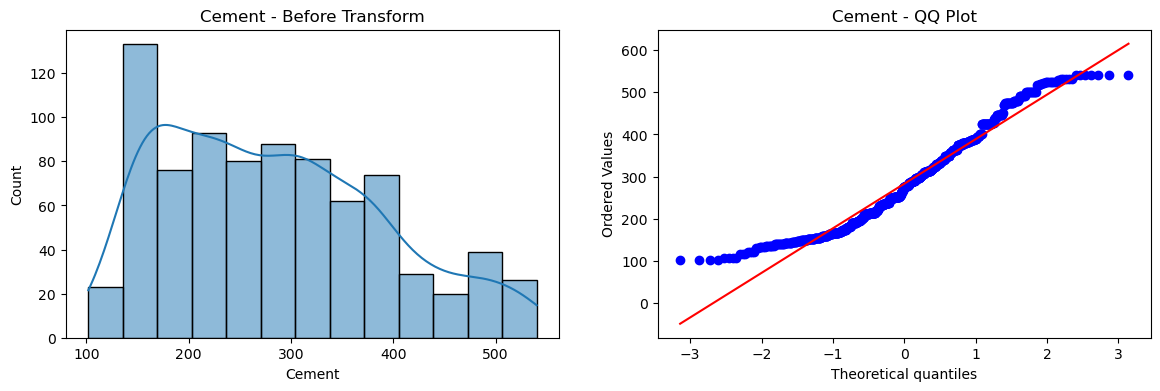

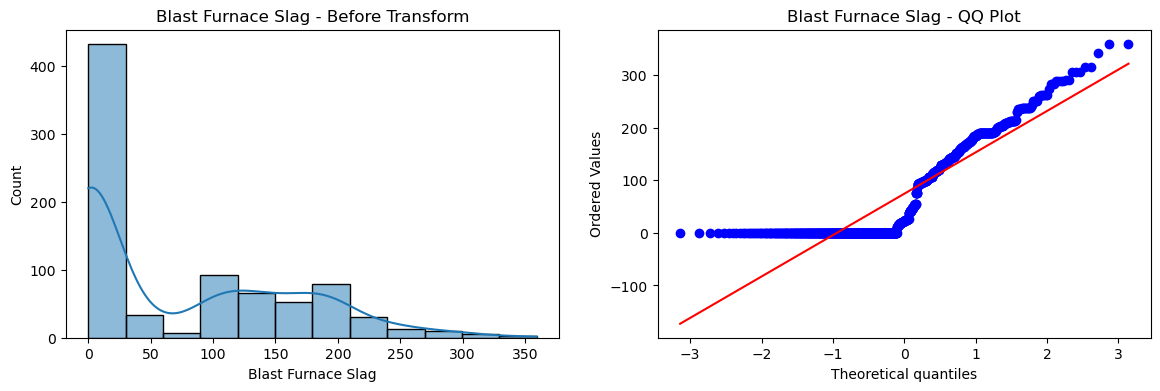

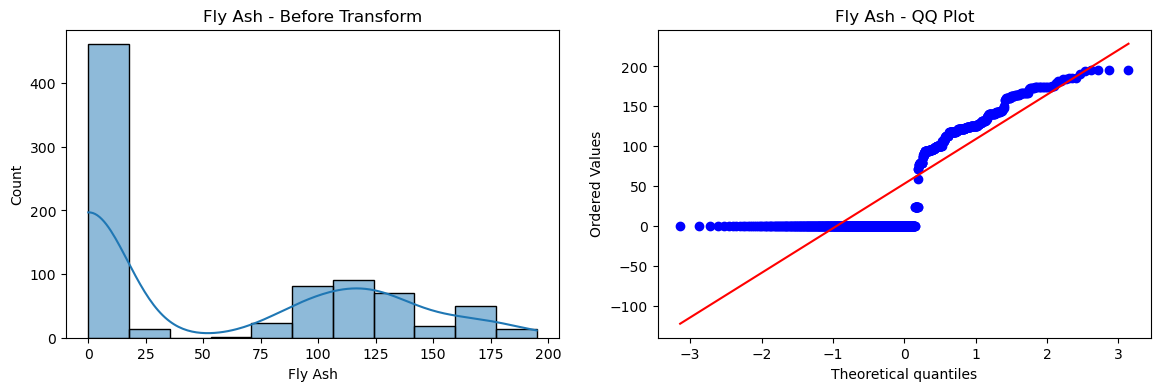

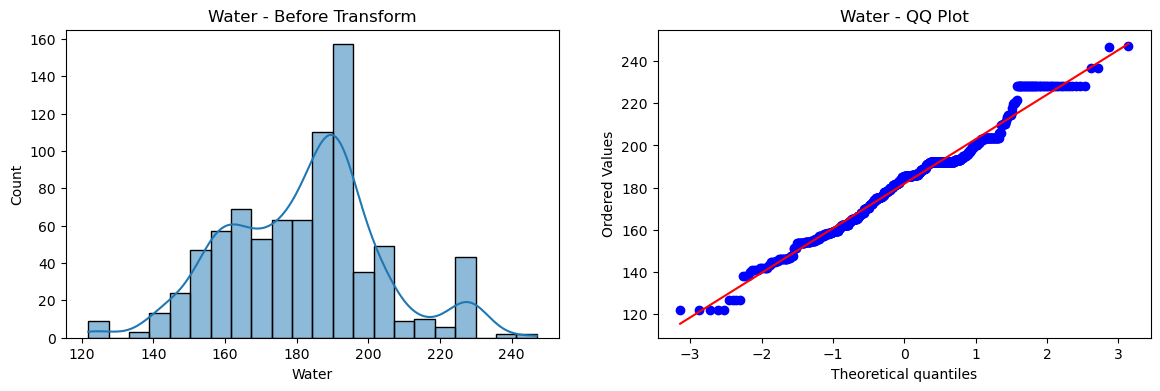

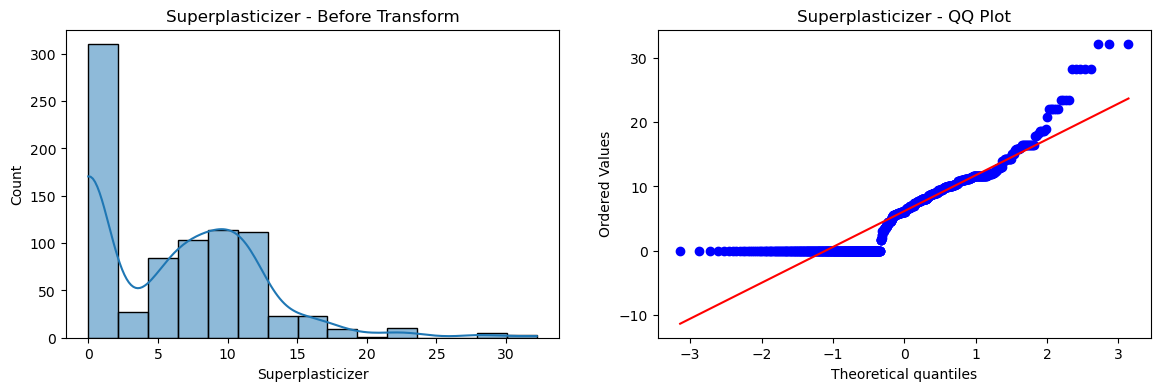

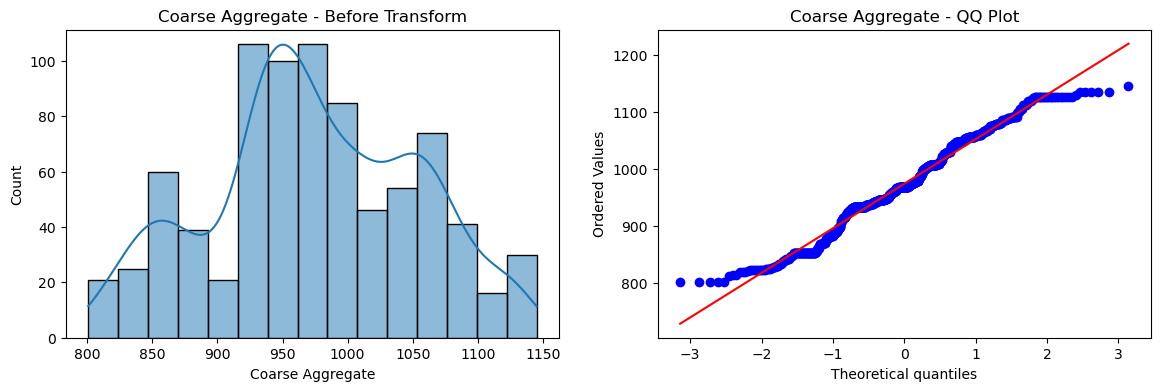

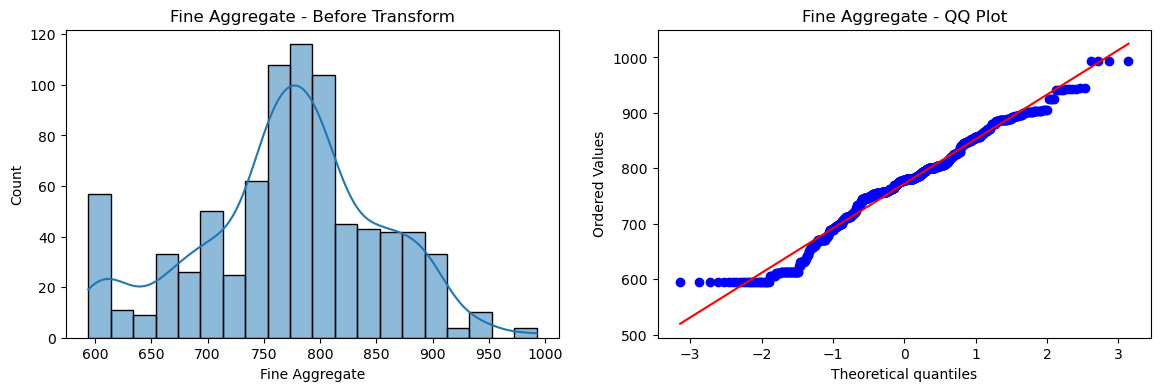

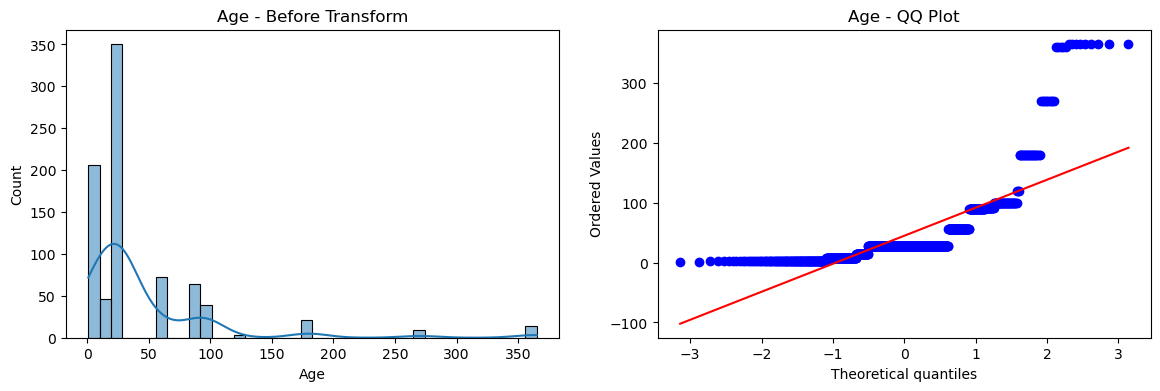

In [10]:
for col in X_train.columns:
    plt.figure(figsize=(14,4))

    plt.subplot(121)
    sns.histplot(X_train[col], kde=True)
    plt.title(f"{col} - Before Transform")

    plt.subplot(122)
    stats.probplot(X_train[col], dist="norm", plot=plt)
    plt.title(f"{col} - QQ Plot")

    plt.show()


In [11]:
pt_boxcox = PowerTransformer(method="box-cox")

X_train_box = pt_boxcox.fit_transform(X_train + 1e-6)
X_test_box = pt_boxcox.transform(X_test + 1e-6)

boxcox_lambdas = pd.DataFrame({
    "cols": X_train.columns,
    "box_cox_lambdas": pt_boxcox.lambdas_
})

boxcox_lambdas


,cols,box_cox_lambdas
0,Cement,0.177025
1,Blast Furnace Slag,0.025093
2,Fly Ash,-0.038970
3,Water,0.772682
4,Superplasticizer,0.098811
5,Coarse Aggregate,1.129813
6,Fine Aggregate,1.782018
7,Age,0.066631


In [12]:
lr = LinearRegression()
lr.fit(X_train_box, y_train)

y_pred_box = lr.predict(X_test_box)

print("✅ R2 with Box-Cox:", r2_score(y_test, y_pred_box))


✅ R2 with Box-Cox: 0.8047825011028631


In [13]:
X_box_all = pt_boxcox.fit_transform(X + 1e-6)

lr = LinearRegression()
box_cv = np.mean(cross_val_score(lr, X_box_all, y, scoring="r2", cv=10))

print("✅ Box-Cox CV R2:", box_cv)


✅ Box-Cox CV R2: 0.6466764736216227


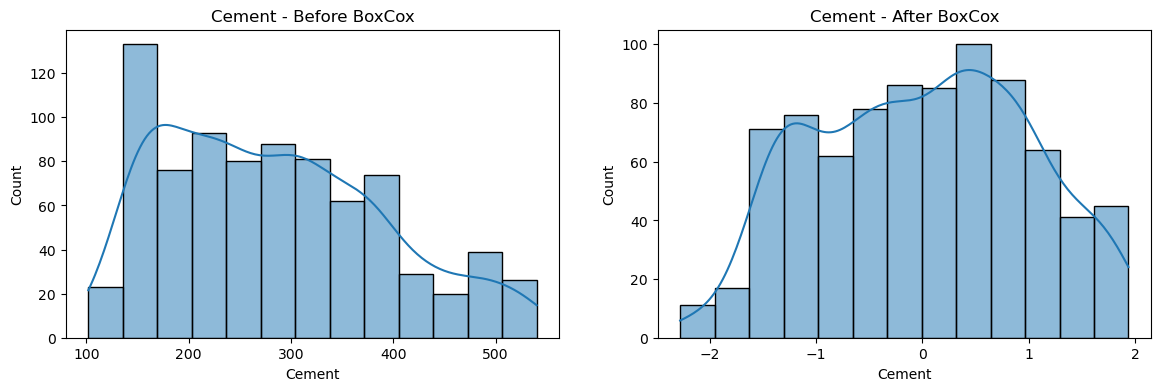

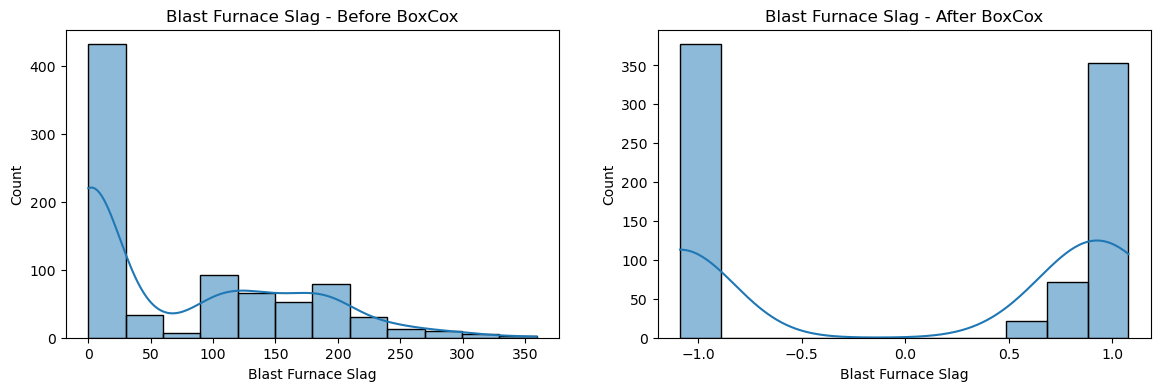

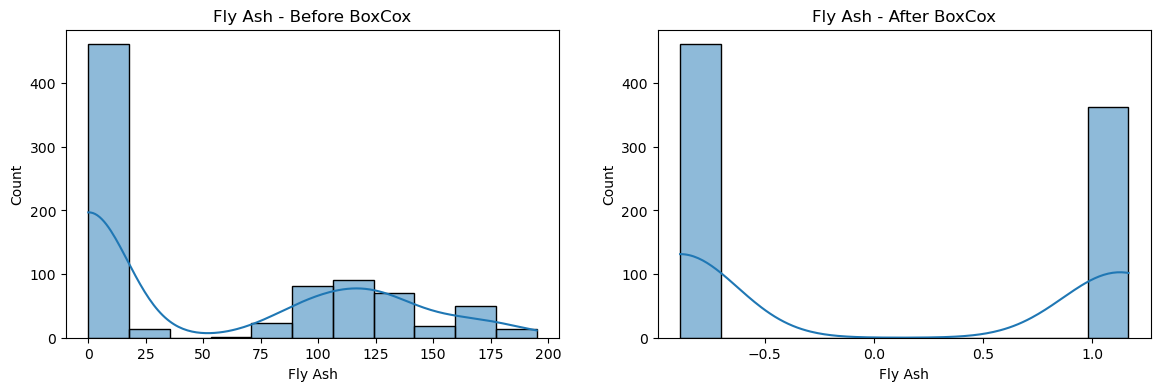

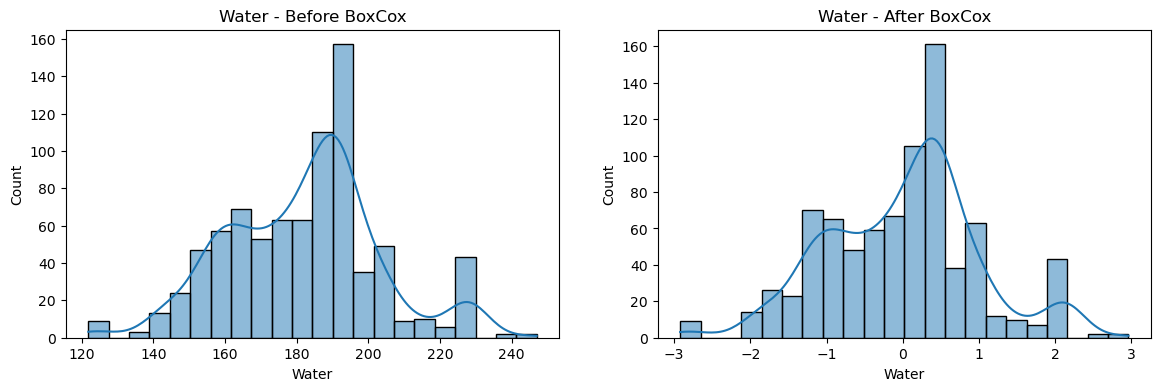

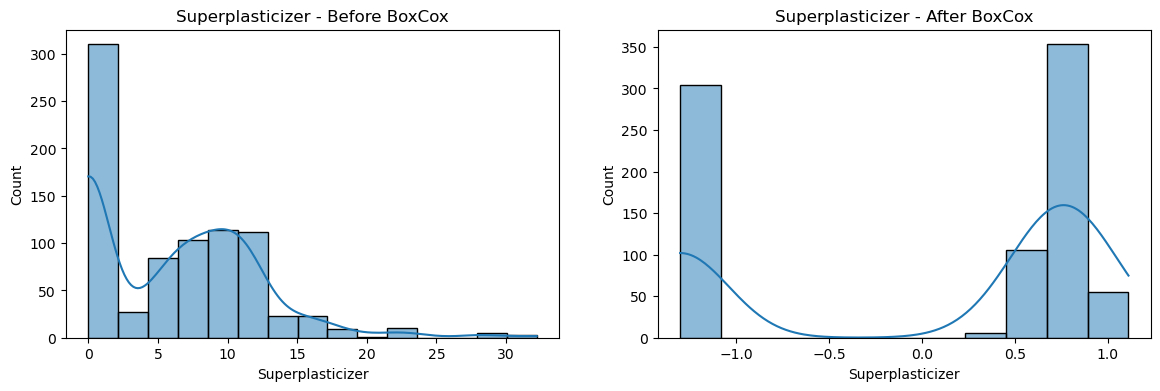

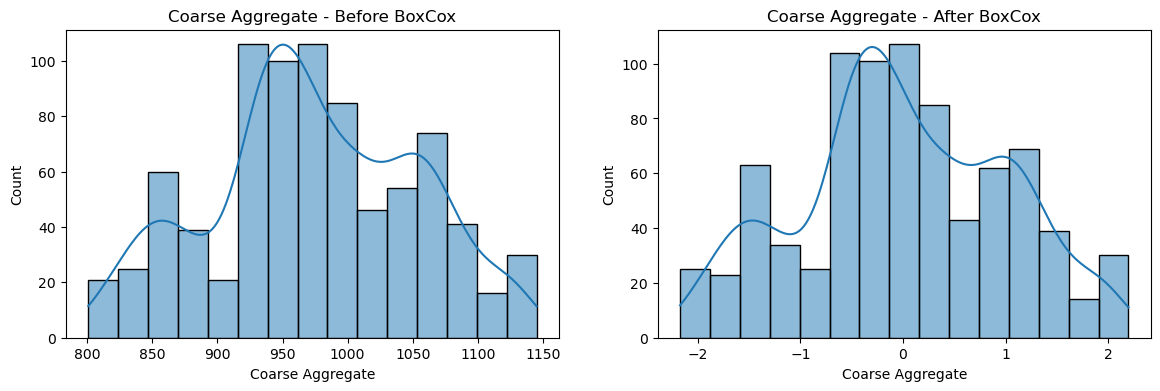

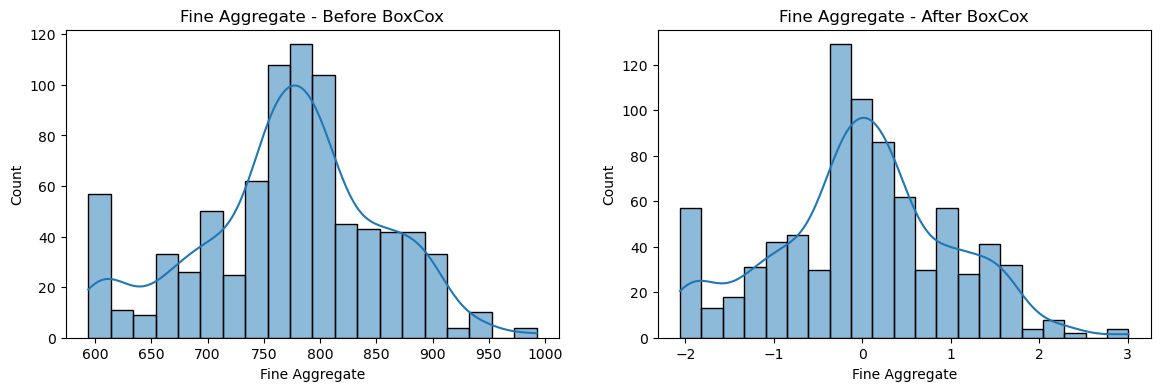

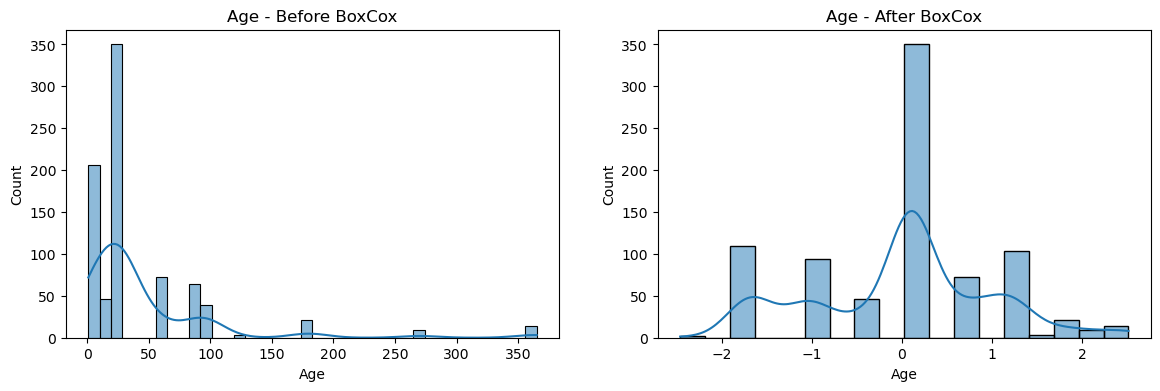

In [14]:
X_train_box_df = pd.DataFrame(X_train_box, columns=X_train.columns)

for col in X_train.columns:
    plt.figure(figsize=(14,4))

    plt.subplot(121)
    sns.histplot(X_train[col], kde=True)
    plt.title(f"{col} - Before BoxCox")

    plt.subplot(122)
    sns.histplot(X_train_box_df[col], kde=True)
    plt.title(f"{col} - After BoxCox")

    plt.show()


# Yeo-Johnson

In [15]:
pt_yj = PowerTransformer(method="yeo-johnson")

X_train_yj = pt_yj.fit_transform(X_train)
X_test_yj = pt_yj.transform(X_test)

yj_lambdas = pd.DataFrame({
    "cols": X_train.columns,
    "yeo_johnson_lambdas": pt_yj.lambdas_
})

yj_lambdas


,cols,yeo_johnson_lambdas
0,Cement,0.174348
1,Blast Furnace Slag,0.015715
2,Fly Ash,-0.161447
3,Water,0.771307
4,Superplasticizer,0.253935
5,Coarse Aggregate,1.130050
6,Fine Aggregate,1.783100
7,Age,0.019885


In [16]:
lr = LinearRegression()
lr.fit(X_train_yj, y_train)

y_pred_yj = lr.predict(X_test_yj)

print("✅ R2 with Yeo-Johnson:", r2_score(y_test, y_pred_yj))


✅ R2 with Yeo-Johnson: 0.8161906513354853


In [17]:
X_yj_all = pt_yj.fit_transform(X)

lr = LinearRegression()
yj_cv = np.mean(cross_val_score(lr, X_yj_all, y, scoring="r2", cv=10))

print("✅ Yeo-Johnson CV R2:", yj_cv)


✅ Yeo-Johnson CV R2: 0.6586548629094919


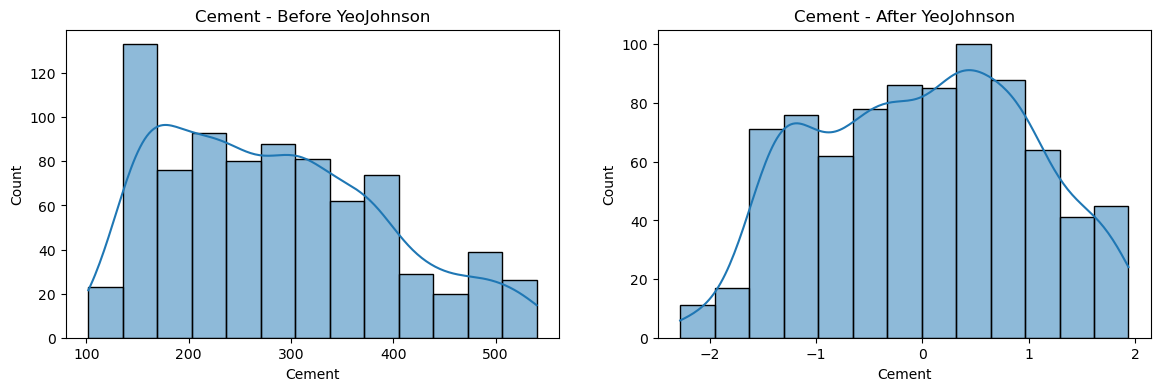

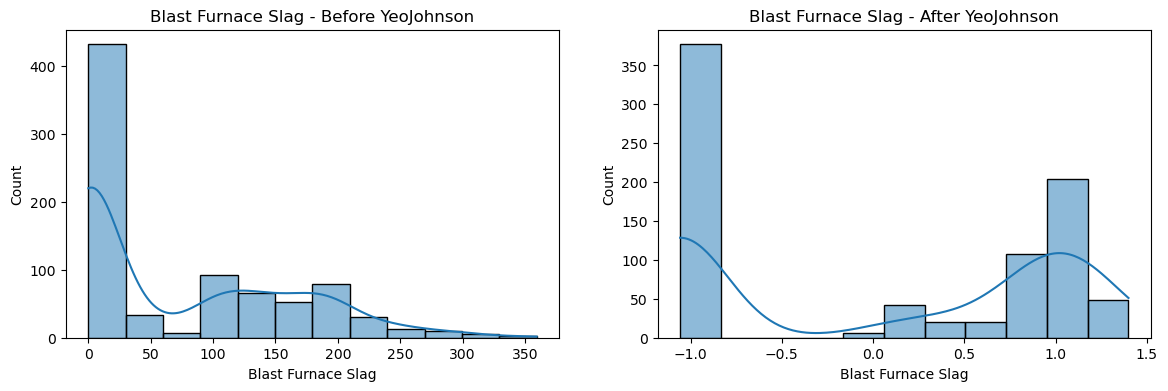

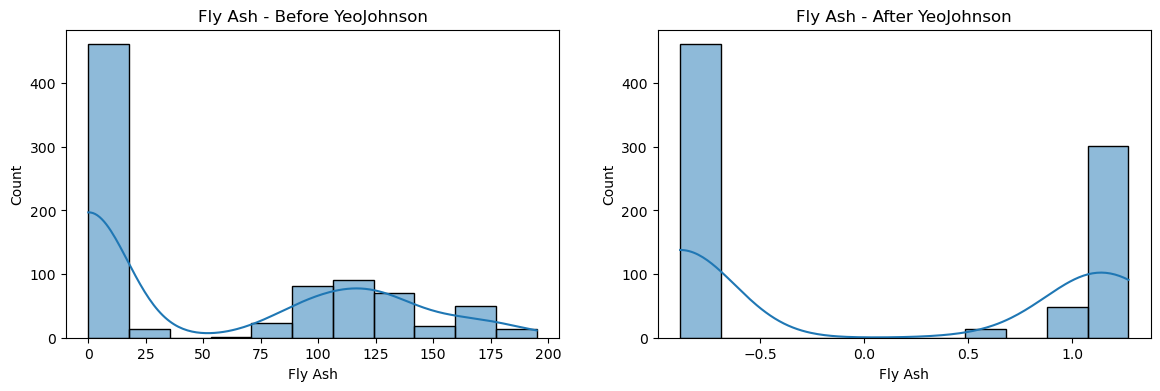

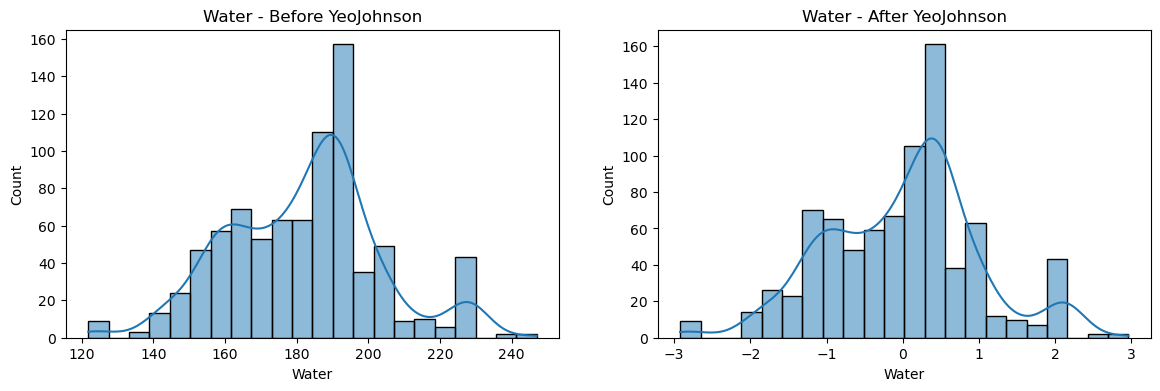

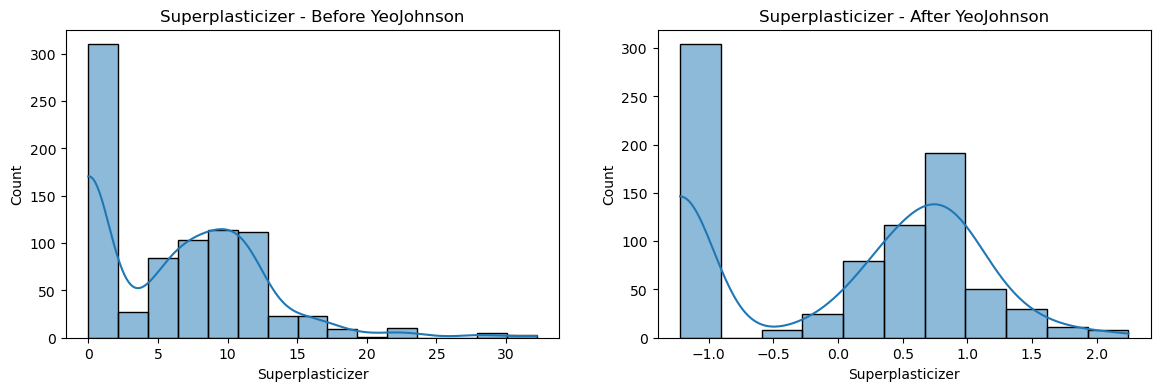

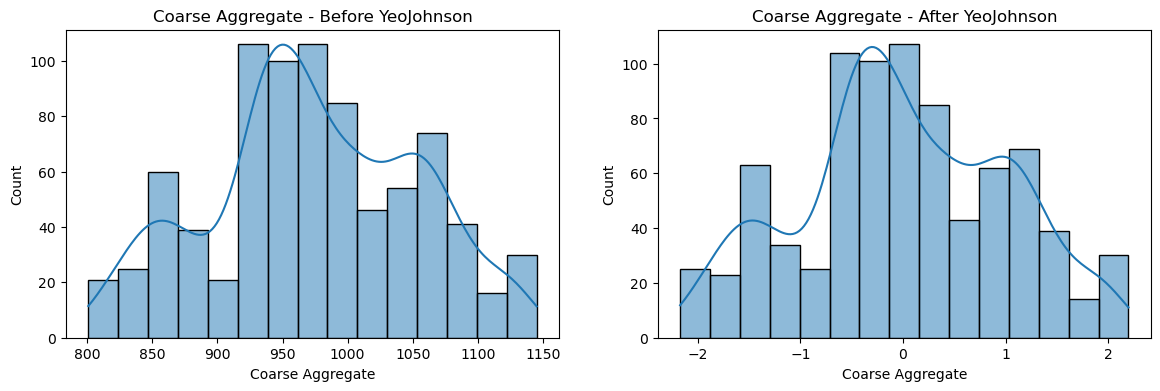

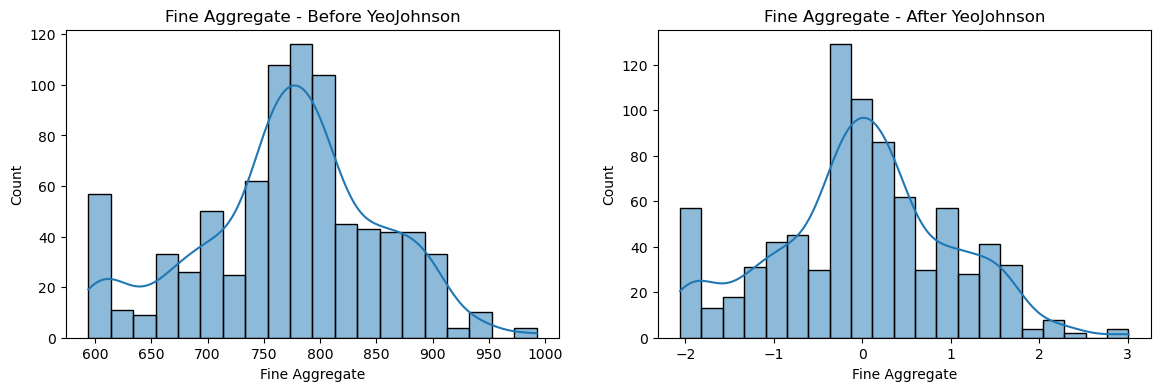

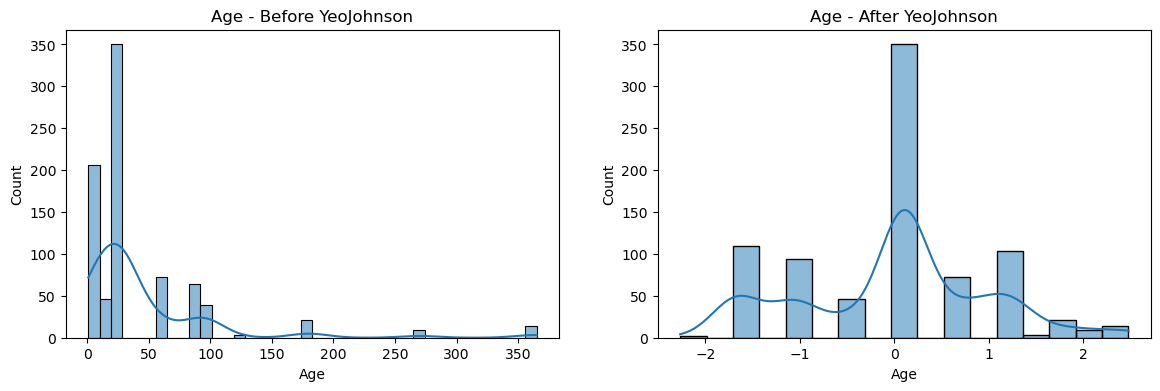

In [18]:
X_train_yj_df = pd.DataFrame(X_train_yj, columns=X_train.columns)

for col in X_train.columns:
    plt.figure(figsize=(14,4))

    plt.subplot(121)
    sns.histplot(X_train[col], kde=True)
    plt.title(f"{col} - Before YeoJohnson")

    plt.subplot(122)
    sns.histplot(X_train_yj_df[col], kde=True)
    plt.title(f"{col} - After YeoJohnson")

    plt.show()


In [19]:
lambda_compare = pd.DataFrame({
    "cols": X_train.columns,
    "box_cox_lambdas": pt_boxcox.lambdas_,
    "yeo_johnson_lambdas": pt_yj.lambdas_
})

lambda_compare


,cols,box_cox_lambdas,yeo_johnson_lambdas
0,Cement,0.172271,0.169544
1,Blast Furnace Slag,0.025273,0.016633
2,Fly Ash,-0.032412,-0.136480
3,Water,0.809568,0.808438
4,Superplasticizer,0.099711,0.264160
5,Coarse Aggregate,1.129168,1.129395
6,Fine Aggregate,1.829625,1.830763
7,Age,0.048975,0.001771


In [20]:
X.skew()


Cement                0.509481
Blast Furnace Slag    0.800717
Fly Ash               0.537354
Water                 0.074628
Superplasticizer      0.907203
Coarse Aggregate     -0.040220
Fine Aggregate       -0.253010
Age                   3.269177
dtype: float64